# 02 — Représentations NLP : du TF-IDF aux Embeddings Denses

Comment transformer un énoncé d'algorithmique et sa solution Python en vecteurs exploitables ? Ce notebook explore et compare deux paradigmes complémentaires :

1. **Représentation creuse classique (TF-IDF)** : principe mathématique, sous-linéarité, choix de lemmatisation, interprétabilité directe des poids appris.
2. **TF-IDF par classe (c-TF-IDF)** : extraire les mots et tokens Python les plus caractéristiques de chacun des 8 tags.
3. **Limites du TF-IDF & Embeddings denses (`all-mpnet-base-v2`)** : encodage contextuel (768 dimensions), clustering **BERTopic** et projection **UMAP 2D**.
4. **Comparaison quantitative (CV 5-folds)** : TF-IDF vs Sentence-BERT sur la même brique linéaire.


In [1]:
import logging
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from umap import UMAP

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import EMBEDDINGS_DIR, SEED, TARGET_TAGS, FeatureConfig, TopicConfig
from src.data import load_modeling_data
from src.evaluate import cross_val_scores
from src.features import (
    CODE_STOP_WORDS,
    CODE_TOKEN_PATTERN,
    TFIDF_CODE_BLOCK,
    TFIDF_DESC_BLOCK,
    benchmark_encoder,
    class_tfidf,
    compute_embeddings,
    embeddings_cache_path,
    get_device,
    load_encoder,
    naive_class_tfidf,
    prepare_descriptions,
    top_terms,
)
from src.models import block_model, build_logreg

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("httpx", "httpx2", "huggingface_hub", "sentence_transformers"):
    logging.getLogger(noisy).setLevel(logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

TOPIC_CFG = TopicConfig()
FEATURE_CFG = FeatureConfig()


/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 15:29:52.251000 55067 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
data = load_modeling_data(TOPIC_CFG)
df, x, y, pos = data.df, data.x, data.y, data.positions
train_df, val_df, test_df = (df.iloc[pos[s]] for s in ("train", "val", "test"))
train_labels = pd.DataFrame(y["train"], index=train_df.index, columns=TARGET_TAGS)
print(f"Jeu nettoyé : {len(df)} exercices | train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")


INFO src.preprocessing: Filtre langue : 4982 -> 4965 exemples


INFO src.preprocessing: Dédoublonnage : 4965 -> 4834 exemples


INFO src.features: Embeddings chargés depuis /Users/ramzi/Documents/illuin-test/data/embeddings/all-mpnet-base-v2__prob_desc_description.npz


Jeu nettoyé : 4834 exercices | train=3383, val=725, test=726


## 1. Comprendre la représentation TF-IDF

### Formulation et intuition
La pondération **TF-IDF** (*Term Frequency – Inverse Document Frequency*) attribue à chaque terme $t$ dans un document $d$ (un exercice) un poids d'autant plus élevé que $t$ apparaît dans cet exercice mais reste rare dans le reste du corpus :

$$\text{TF-IDF}(t, d) = \text{tf}_{\text{sublin}}(t, d) \times \text{idf}(t), \qquad \text{avec}\quad \text{tf}_{\text{sublin}}(t, d) = 1 + \log(\text{count}(t, d)), \quad \text{idf}(t) = \log\left(\frac{1 + N}{1 + \text{df}(t)}\right) + 1$$

**Trois choix méthodologiques clés sur ce dataset :**
1. **TF sublinéaire (`sublinear_tf=True`)** : qu'un mot ou un appel de fonction (`append`, `modulo`) soit répété 3 fois ou 50 fois dans un même exercice, son poids croît logarithmiquement afin d'éviter qu'un long bloc de code n'écrase la représentation.
2. **Lemmatisation sur les descriptions, brute sur le code** : pour la description (`prepare_description`), la lemmatisation WordNet regroupe *vertex / vertices* et *string / strings* dans une seule colonne. Sur le code Python, on garde les identifiants sensibles à la casse et on filtre les mots-clés Python + I/O (`CODE_STOP_WORDS`), tout en conservant des appels informatifs (`gcd`, `pow`, `ord`, `deque`).
3. **Zéro fuite** : le vocabulaire et les poids IDF sont appris **exclusivement sur le split d'entraînement** (ou sur le train de chaque fold en CV).


In [3]:
# Ajustement des vectoriseurs TF-IDF sur le train uniquement
desc_vec = TfidfVectorizer(
    stop_words="english", min_df=FEATURE_CFG.tfidf_desc_min_df, sublinear_tf=True
)
X_tfidf_desc = desc_vec.fit_transform(prepare_descriptions(train_df["prob_desc_description"].to_numpy()))

code_vec = TfidfVectorizer(
    token_pattern=CODE_TOKEN_PATTERN,
    lowercase=False,
    stop_words=CODE_STOP_WORDS,
    min_df=FEATURE_CFG.tfidf_code_min_df,
    sublinear_tf=True,
)
X_tfidf_code = code_vec.fit_transform(train_df["source_code"].fillna(""))

stats = pd.DataFrame(
    {
        "vocabulaire (colonnes)": [X_tfidf_desc.shape[1], X_tfidf_code.shape[1]],
        "moy. termes actifs / ex.": [X_tfidf_desc.getnnz(axis=1).mean(), X_tfidf_code.getnnz(axis=1).mean()],
        "sparsité (%)": [
            100 * (1 - X_tfidf_desc.nnz / np.prod(X_tfidf_desc.shape)),
            100 * (1 - X_tfidf_code.nnz / np.prod(X_tfidf_code.shape)),
        ],
    },
    index=["description (lemmatisée)", "source_code (tokens)"],
).round(2)
display(stats)

idf_s = pd.Series(desc_vec.idf_, index=desc_vec.get_feature_names_out()).sort_values()
print("Termes les plus transverses (IDF minimale) :", idf_s.head(10).round(2).to_dict())
print("Termes très spécifiques (IDF élevée, min_df=10) :", idf_s.tail(10).round(2).to_dict())


,vocabulaire (colonnes),moy. termes actifs / ex.,sparsité (%)
description (lemmatisée),1812,33.88,98.13
source_code (tokens),1671,20.22,98.79


Termes les plus transverses (IDF minimale) : {'number': 1.45, 'ha': 1.75, 'given': 1.82, 'integer': 1.88, 'want': 2.15, 'possible': 2.21, 'time': 2.24, 'example': 2.31, 'help': 2.32, 'following': 2.34}
Termes très spécifiques (IDF élevée, min_df=10) : {'studied': 6.73, 'unlike': 6.73, 'preparation': 6.73, 'iahub': 6.73, 'activity': 6.73, 'consisted': 6.73, 'currency': 6.73, 'entry': 6.73, 'rotating': 6.73, 'forgotten': 6.73}


In [4]:
# Interprétabilité directe : poids appris par une régression logistique sur TF-IDF (description)
tfidf_pipe = block_model(TFIDF_DESC_BLOCK, FEATURE_CFG).fit(
    train_df["prob_desc_description"].fillna("").to_numpy(dtype=object), y["train"]
)
vocab = tfidf_pipe.named_steps["tfidfvectorizer"].get_feature_names_out()
coefs = pd.DataFrame(
    [est.coef_[0] for est in tfidf_pipe.named_steps["onevsrestclassifier"].estimators_],
    index=TARGET_TAGS,
    columns=vocab,
)
pd.DataFrame(
    {tag: [f"{w} ({coefs.at[tag, w]:+.2f})" for w in coefs.loc[tag].nlargest(6).index] for tag in TARGET_TAGS},
    index=pd.RangeIndex(1, 7, name="rang"),
)


,math,graphs,strings,number theory,trees,geometry,games,probabilities
rang,,,,,,,,
1,divisible (+2.49),road (+3.99),string (+8.64),divisor (+5.96),tree (+7.98),point (+7.24),turn (+6.25),probability (+10.02)
2,sum (+2.45),graph (+3.87),letter (+4.39),prime (+5.23),vertex (+4.06),plane (+5.05),player (+5.90),expected (+6.26)
3,frac (+2.33),connected (+3.60),word (+4.02),gcd (+4.12),connected (+3.99),angle (+4.83),optimally (+5.10),randomly (+3.99)
4,cdot (+2.10),edge (+3.08),oplus (+2.64),divisible (+3.64),node (+3.95),coordinate (+3.38),win (+4.74),equiprobably (+3.92)
5,number (+2.10),vertex (+2.96),english (+2.27),cdot (+3.53),path (+3.31),polygon (+3.09),play (+4.03),random (+3.64)
6,modulo (+2.04),city (+2.51),text (+2.21),integer (+3.03),road (+2.89),radius (+3.05),game (+3.98),calculate (+2.78)


## 2. TF-IDF par classe (c-TF-IDF) : quel vocabulaire caractérise chaque tag ?

Démarche inverse : on part des **8 tags** (plus un groupe référence « aucun tag cible ») pour identifier les mots et tokens distinctifs.

**Pourquoi la version naïve échoue :** si l'on concatène simplement les textes en 9 méga-documents puis qu'on applique une TF-IDF classique (`naive_class_tfidf`), l'IDF est calculée sur 9 documents seulement : des mots présents partout (*number*, *array*, *given*) conservent une IDF quasi plate et dominent le classement.

**La variante retenue (`src/features.py: class_tfidf`) :**

$$\text{score}(\text{terme}, \text{tag}) = \text{part des exercices du tag contenant le terme} \times \log\left(\frac{N}{\text{nb d'exercices contenant le terme}}\right)$$

La présence **binaire** par exercice empêche un template copié-collé de peser 50 fois, et l'**IDF globale** sur les ~4 800 exercices pénalise réellement les termes banals.


=== Version naïve (9 documents de classe, biaisée vers les mots fréquents) ===


,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
rang,,,,,,,,,
1,number,vertex,string,number,vertex,point,player,probability,number
2,integer,number,letter,integer,tree,polygon,game,number,ha
3,array,road,number,array,number,coordinate,turn,value,array
4,ha,edge,character,given,node,segment,play,integer,integer
5,given,city,length,le,edge,ha,card,ha,th
6,element,graph,substring,positive,path,number,number,game,time


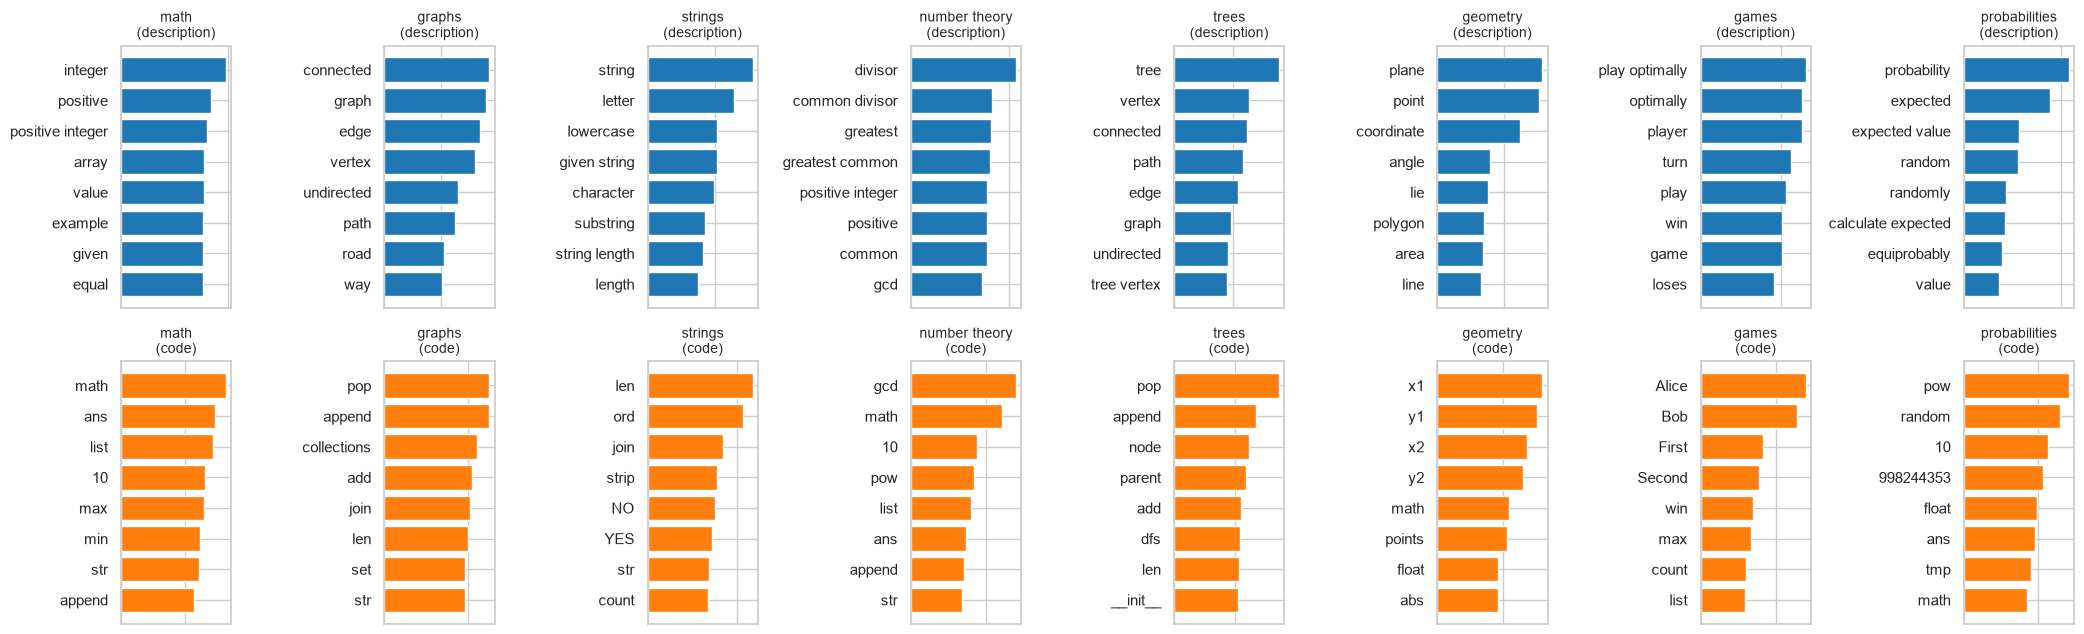

In [5]:
Y_all = pd.DataFrame(
    {t: df["tags"].apply(lambda ts, t=t: t in ts) for t in TARGET_TAGS}, index=df.index
).astype(int)

print("=== Version naïve (9 documents de classe, biaisée vers les mots fréquents) ===")
display(top_terms(naive_class_tfidf(df["text_lemma"], Y_all, stop_words="english"), 6))

desc_scores = class_tfidf(df["text_lemma"], Y_all, stop_words="english", ngram_range=(1, 2))
code_scores = class_tfidf(
    df["source_code"], Y_all, token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS
)

fig, axes = plt.subplots(2, len(TARGET_TAGS), figsize=(21, 6.5))
for row, (source, scores) in enumerate({"description": desc_scores, "code": code_scores}.items()):
    for ax, tag in zip(axes[row], TARGET_TAGS):
        top = scores.loc[tag].nlargest(8)[::-1]
        ax.barh(top.index, top.values, color="tab:blue" if row == 0 else "tab:orange")
        ax.set_title(f"{tag}\n({source})", fontsize=10)
        ax.tick_params(axis="x", labelbottom=False)
plt.tight_layout()
plt.show()


**Lecture du vocabulaire discriminant :**
- **7 tags sur 8** ont des marqueurs lexicaux très nets dans l'énoncé (`strings` → *letter, lowercase* ; `games` → *play optimally, turns* ; `geometry` → *plane, polygon, coordinate* ; `probabilities` → *probability, expected value*).
- **`math` fait exception** dans l'énoncé (*integer, positive, array* : termes génériques). En revanche, **le code source le trahit** (`math`, `gcd`, `pow`), tout comme `probabilities` (`998244353`, `pow`, `mod`) ou `games` (`Alice`, `Bob`).
- `graphs` et `trees` partagent `pop`, `append` et `collections` (parcours BFS/DFS), expliquant leurs co-occurrences.


## 3. Limites du TF-IDF & Embeddings Denses (Sentence-BERT)

Le TF-IDF traite chaque mot comme une colonne orthogonale : il ne rapproche pas les synonymes (*chance* vs *probability*), ne saisit pas le sens d'une phrase complète et reste trompé par l'habillage narratif des énoncés.

On passe donc à des **embeddings sémantiques denses** via Sentence-BERT (`all-mpnet-base-v2`, 768 dimensions), puis on inspecte la structure géométrique de cet espace par **BERTopic (UMAP + HDBSCAN)** et projection **UMAP 2D**.


In [6]:
encoder = load_encoder(TOPIC_CFG.embedding_model)
texts = df["text_clean"].tolist()

n_tokens = pd.Series([len(ids) for ids in encoder.tokenizer(texts)["input_ids"]])
print(f"device={get_device()} | max_seq_length={encoder.max_seq_length} | dim={encoder.get_sentence_embedding_dimension()}")
print(f"Textes tronqués : {(n_tokens > encoder.max_seq_length).mean():.1%} (médiane {n_tokens.median():.0f} tokens)")

sample = df["text_clean"].sample(256, random_state=SEED).tolist()
per_text = benchmark_encoder(encoder, sample, TOPIC_CFG.batch_size)
print(f"Vitesse d'encodage : {per_text * 1000:.1f} ms/texte (~{per_text * len(texts):.0f} s pour {len(texts)} textes)")

cache_path = embeddings_cache_path(EMBEDDINGS_DIR, TOPIC_CFG.embedding_model, "prob_desc_description")
embeddings = compute_embeddings(
    texts, df.index.to_numpy(), encoder, cache_path, TOPIC_CFG.embedding_model, TOPIC_CFG.batch_size
)
print("Embeddings prêts :", embeddings.shape)


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 199/199 [00:00<00:00, 11577.15it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (396 > 384). Running this sequence through the model will result in indexing errors


device=mps | max_seq_length=384 | dim=768
Textes tronqués : 2.9% (médiane 173 tokens)


INFO src.features: Embeddings chargés depuis /Users/ramzi/Documents/illuin-test/data/embeddings/all-mpnet-base-v2__prob_desc_description.npz


Vitesse d'encodage : 17.8 ms/texte (~86 s pour 4834 textes)
Embeddings prêts : (4834, 768)


61 topics | outliers HDBSCAN (-1) : 35.1%


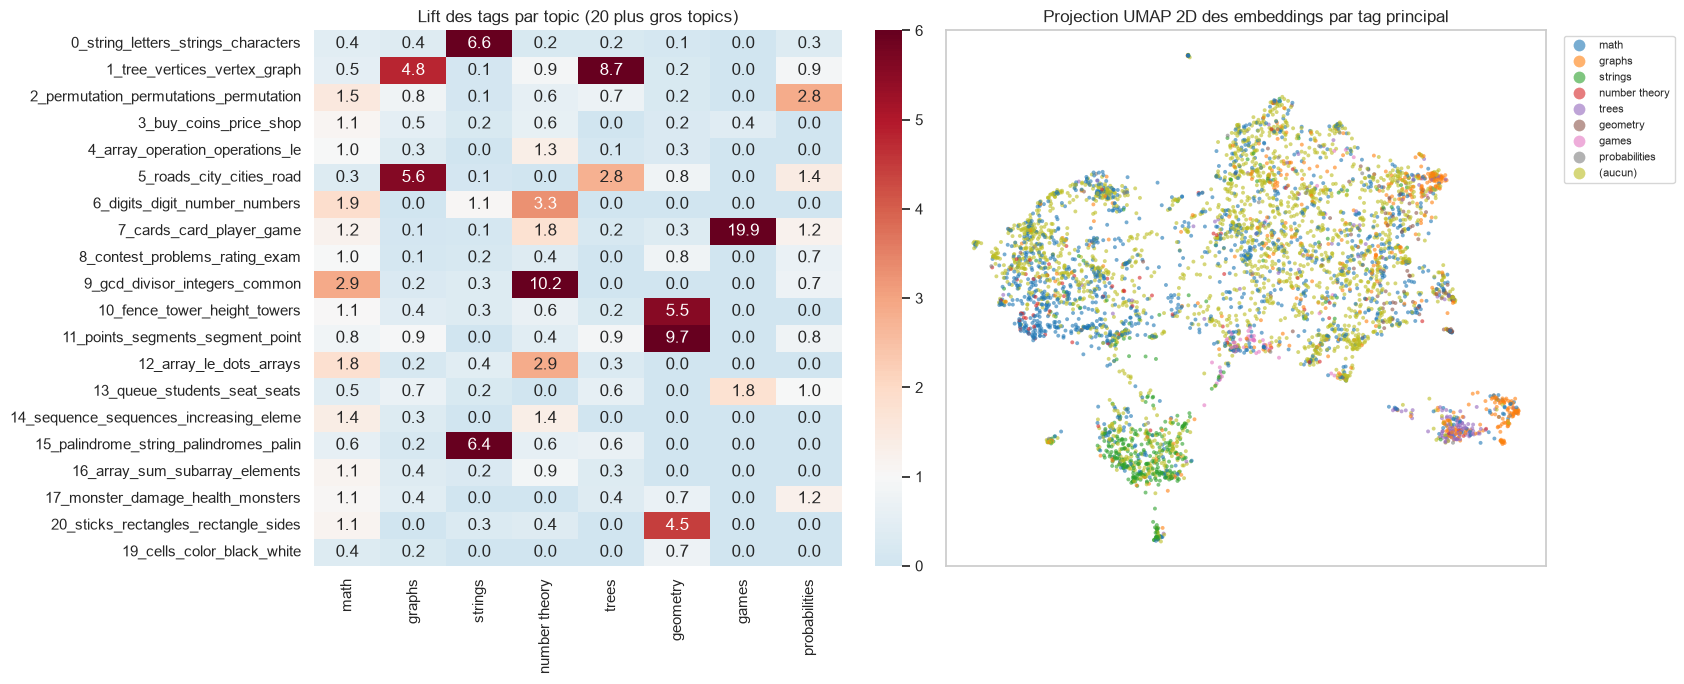

In [7]:
# Clustering exploratoire BERTopic (UMAP 5D + HDBSCAN) sur les embeddings
topic_model = BERTopic(
    umap_model=UMAP(
        n_neighbors=TOPIC_CFG.umap_n_neighbors,
        n_components=TOPIC_CFG.umap_n_components,
        metric="cosine",
        random_state=SEED,
    ),
    hdbscan_model=HDBSCAN(
        min_cluster_size=TOPIC_CFG.hdbscan_min_cluster_size,
        min_samples=TOPIC_CFG.hdbscan_min_samples,
        metric="euclidean",
        prediction_data=True,
    ),
    vectorizer_model=CountVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2)),
    calculate_probabilities=False,
)
topics, _ = topic_model.fit_transform(texts, embeddings)
df["topic"] = topics

clustered = df["topic"] != -1
print(f"{(topic_model.get_topic_info()['Topic'] != -1).sum()} topics | outliers HDBSCAN (-1) : {(~clustered).mean():.1%}")

share = Y_all[clustered].groupby(df.loc[clustered, "topic"]).mean()
lift = share / Y_all.mean()
top_topics = df.loc[clustered, "topic"].value_counts().head(20).index
labels = [topic_model.get_topic_info(t)["Name"].iloc[0][:38] for t in top_topics]

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(lift.loc[top_topics].set_axis(labels), cmap="RdBu_r", center=1, vmax=6, annot=True, fmt=".1f", ax=axes[0])
axes[0].set(title="Lift des tags par topic (20 plus gros topics)", xlabel="", ylabel="")

coords = UMAP(n_neighbors=15, n_components=2, metric="cosine", random_state=SEED).fit_transform(embeddings)
main_tag = Y_all.idxmax(axis=1).where(Y_all.sum(axis=1) > 0, "(aucun)")
sns.scatterplot(
    x=coords[:, 0], y=coords[:, 1], hue=main_tag, hue_order=TARGET_TAGS + ["(aucun)"],
    palette="tab10", s=8, alpha=0.6, linewidth=0, ax=axes[1],
)
axes[1].set(title="Projection UMAP 2D des embeddings par tag principal", xticks=[], yticks=[])
axes[1].legend(markerscale=3, bbox_to_anchor=(1.02, 1), fontsize=8)
plt.tight_layout()
plt.show()


## 4. Match direct : TF-IDF vs Embeddings (Validation croisée 5-folds)

On compare maintenant les deux familles de représentations avec **le même classifieur linéaire** (8 régressions logistiques One-vs-Rest régularisées $L_2$) en validation croisée stratifiée 5-folds sur `train + val` (critère sans seuil : **Macro-AP**). Dans chaque fold, la TF-IDF est ajustée uniquement sur les 4 folds d'entraînement.


In [8]:
x_dev_sbert, y_dev = data.dev()
dev_df = pd.concat([train_df, val_df])
raw_desc_dev = dev_df["prob_desc_description"].fillna("").to_numpy(dtype=object)
raw_code_dev = dev_df["source_code"].fillna("").to_numpy(dtype=object)

# Sensibilité à la régularisation C pour les représentations creuses TF-IDF
tfidf_tuning = []
for block, raw_x in [(TFIDF_DESC_BLOCK, raw_desc_dev), (TFIDF_CODE_BLOCK, raw_code_dev)]:
    for C in (0.1, 0.3, 1.0, 3.0, 10.0):
        cfg = replace(FEATURE_CFG, tfidf_desc_C=C, tfidf_code_C=C)
        scores = cross_val_scores(
            lambda xt, yt, xe, ye, b=block, c=cfg: block_model(b, c).fit(xt, yt).predict_proba(xe),
            raw_x, y_dev, n_splits=5,
        )
        tfidf_tuning.append({"bloc": block, "C": C, "cv_macro_ap": np.mean(scores), "cv_std": np.std(scores)})

tfidf_cv = pd.DataFrame(tfidf_tuning)
display(tfidf_cv.pivot(index="C", columns="bloc", values="cv_macro_ap").round(4))


bloc,tfidf_code,tfidf_desc
C,,
0.1,0.3176,0.5658
0.3,0.3174,0.5753
1.0,0.3110,0.5809
3.0,0.2957,0.5759
10.0,0.2756,0.5627


,représentation,cv_macro_ap,cv_std
0,TF-IDF code (C=0.1),0.3176,0.0133
1,TF-IDF description (C=1.0),0.5809,0.0235
2,Sentence-BERT description (C=1.0),0.5904,0.0334


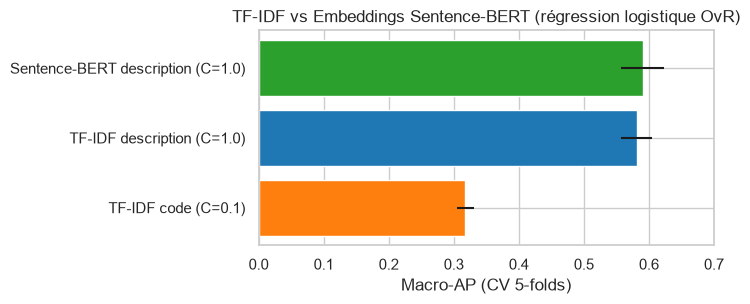

In [9]:
sbert_scores = cross_val_scores(
    lambda xt, yt, xe, ye: build_logreg().fit(xt, yt).predict_proba(xe),
    x_dev_sbert, y_dev, n_splits=5,
)
best_desc = tfidf_cv[tfidf_cv["bloc"] == TFIDF_DESC_BLOCK].sort_values("cv_macro_ap", ascending=False).iloc[0]
best_code = tfidf_cv[tfidf_cv["bloc"] == TFIDF_CODE_BLOCK].sort_values("cv_macro_ap", ascending=False).iloc[0]

summary_nlp = pd.DataFrame(
    [
        {"représentation": f"TF-IDF code (C={best_code['C']})", "cv_macro_ap": best_code["cv_macro_ap"], "cv_std": best_code["cv_std"]},
        {"représentation": f"TF-IDF description (C={best_desc['C']})", "cv_macro_ap": best_desc["cv_macro_ap"], "cv_std": best_desc["cv_std"]},
        {"représentation": "Sentence-BERT description (C=1.0)", "cv_macro_ap": np.mean(sbert_scores), "cv_std": np.std(sbert_scores)},
    ]
)
display(summary_nlp.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(summary_nlp["représentation"], summary_nlp["cv_macro_ap"], xerr=summary_nlp["cv_std"], color=["tab:orange", "tab:blue", "tab:green"])
ax.set(xlim=(0, 0.7), xlabel="Macro-AP (CV 5-folds)", title="TF-IDF vs Embeddings Sentence-BERT (régression logistique OvR)")
plt.tight_layout()
plt.show()


### Constats clés de l'analyse NLP
- **La TF-IDF de description fait presque jeu égal avec Sentence-BERT** (**0,581** vs **0,590** de Macro-AP). Le vocabulaire précis (*play optimally*, *polygon*, *gcd*) est un signal très fort que l'embedding moyenné dilue légèrement.
- **BERTopic** forme des clusters cohérents sur les tags narratifs (`strings`, `trees`, `games`, `geometry`), mais laisse 35 % d'outliers et échoue sur `math` et `probabilities` : la supervision reste indispensable.
- **TF-IDF sur le code seul est plus faible (`0,318`)** : les noms de variables propres à chaque auteur et les tokens partagés (`pow`) limitent le sac de mots. Un encodeur contextuel de code (**UniXcoder**) sera nécessaire au Notebook 04.
- **Complémentarité** : le gain potentiel de combiner embeddings denses + TF-IDF lexicale sera évalué en stacking au Notebook 04.
